# Notebook Dedicated to Study Electron Simulation Observables

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sn

# Load the Data

In [2]:
fdir = '/home/joankl/data/solars/mc/2p2PPO/electrons/e_5.0MeV_0.npz'

data = np.load(fdir)
print(f'List of Variables on data file: \n {list(data.keys())}')

# Load PMT Data Base (DB)
pmt_db = data['pmt_db']
pmt_db_id = pmt_db[:,0]
pmt_db_pos_x, pmt_db_pos_y, pmt_db_pos_z = pmt_db[:,1], pmt_db[:,2], pmt_db[:,3]
pmt_db_type = pmt_db[:,4]

# Load Simulated Event's Data
energy_mc = data['energy_mc']
energy_recon = data['energy_recon']

posx_mc, posy_mc, posz_mc = data['pos_mc'][:,0], data['pos_mc'][:,1], data['pos_mc'][:,2]   # Simulated event position
posx_recon, posy_recon, posz_recon = data['pos_recon'][:,0], data['pos_recon'][:,1], data['pos_recon'][:,2] # Reconstructed event position

time_residual_mc = data['time_residual_mc'] # Time residual computed using mc (true) quantities (true events position and event time)
time_residual_recons = data['time_residual_recons'] # Time residual computed using reconstructed quantites

hit_time = data['hit_time']  # PMT Hits times

dir_angle_true_recons = data['dir_angle_true_recons'] # directional observable (cos (chev. angle)) obtained from reconstructed event position
dir_angle_true_mc = data['dir_angle_true_mc'] # directional observable (cos (chev. angle)) obtained from true event position
dir_angle_sun = data['dir_angle_sun'] # directional observable (cos (chev. angle)) obtained from the Sun direnction (doesn't corresponde to true simulated event direction)

hit_qhs = data['hit_qhs']  # PMT Charge QHS (High-Gain Short Interval)
hit_qhl = data['hit_qhl']  # PMT Charge QHL (High-Gain Long Interval)

hit_type = data['hit_type']  # mask to separate cherenkov hits from scint. hits (type=1 is chev, type=2 is scint., and type=3 is chev+scint.)


List of Variables on data file: 
 ['pmt_db', 'evtid', 'mcid', 'energy_mc', 'energy_recon', 'pos_mc', 'pos_recon', 'dir_mc', 'sun_dir', 'hit_pmt_id', 'hit_time', 'time_residual_mc', 'time_residual_recons', 'hit_qhs', 'hit_qhl', 'hit_type', 'dir_angle_true_recons', 'dir_angle_true_mc', 'dir_angle_sun']


In [3]:
hit_type.shape

(1360921,)

In [4]:
dir_angle_true_recons.shape

(1360921,)

# Plots

## Energy

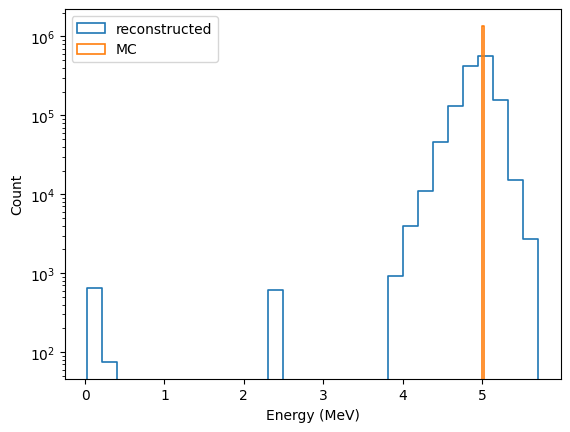

In [5]:
sn.histplot(energy_recon, bins = 30, element = 'step', alpha = 0, lw = 1.2, label = 'reconstructed')
sn.histplot(energy_mc, bins = 30, element = 'step', alpha = 0, lw = 1.2, label = 'MC')

plt.yscale('log')
plt.xlabel('Energy (MeV)')
plt.legend()
plt.show()

## Directionality

### All hit PMTs

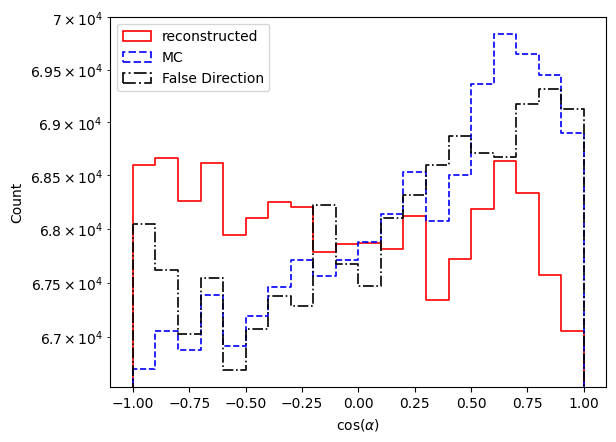

In [6]:
bins = 20

sn.histplot(dir_angle_true_recons, bins = bins, element = 'step', alpha = 0, lw = 1.2, label = 'reconstructed', color = 'red')
sn.histplot(dir_angle_true_mc, bins = bins, element = 'step', alpha = 0, lw = 1.2, label = 'MC', linestyle = '--', color = 'blue')
sn.histplot(dir_angle_sun, bins = bins, element = 'step', alpha = 0, lw = 1.2, label = 'False Direction', linestyle = '-.', color = 'black')

plt.yscale('log')
plt.xlabel(r'$\cos(\alpha)$')
plt.legend()
plt.show()

### Hit PMTs Selection

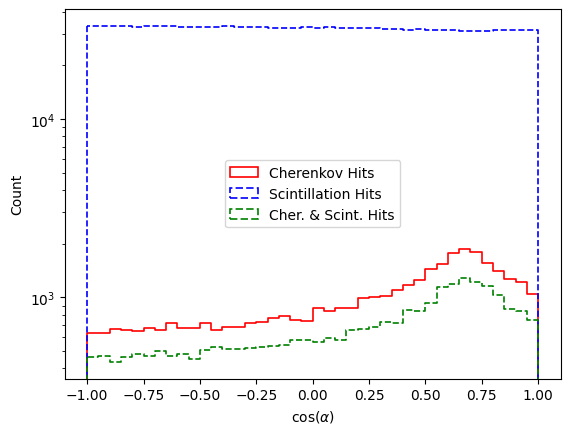

In [181]:
cher_hits_condition = (hit_type == 1)
scint_hits_condition = (hit_type == 2)
cher_plus_scint_hits_condition = (hit_type == 3)

dir_angle_cher = dir_angle_true_recons[cher_hits_condition]
dir_angle_scint = dir_angle_true_recons[scint_hits_condition]
dir_angle_cher_plus_scint = dir_angle_true_recons[cher_plus_scint_hits_condition]

sn.histplot(dir_angle_cher, bins = bins, element = 'step', alpha = 0, lw = 1.2, label = 'Cherenkov Hits', color = 'red')
sn.histplot(dir_angle_scint, bins = bins, element = 'step', alpha = 0, lw = 1.2, label = 'Scintillation Hits', linestyle = '--', color = 'blue')
sn.histplot(dir_angle_cher_plus_scint, bins = bins, element = 'step', alpha = 0, lw = 1.2, label = 'Cher. & Scint. Hits', linestyle = '--', color = 'Green')

plt.yscale('log')
plt.xlabel(r'$\cos(\alpha)$')
plt.legend()
plt.show()

## Time Residual

In [182]:
# Set Time residual cuts for the following plots
tres_min = -4
tres_max = 1

### Hit PMTs Selection

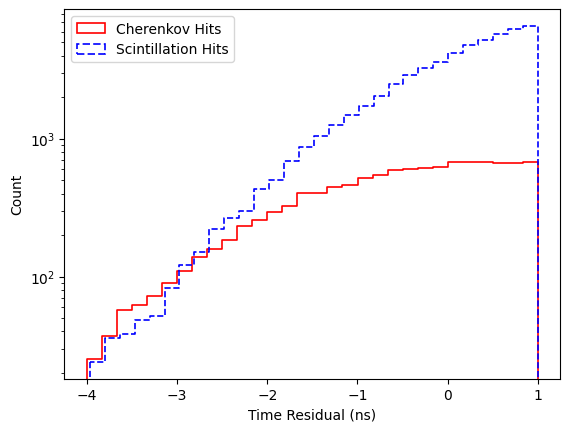

In [183]:
bins = 30

time_residual_cher = time_residual_recons[cher_hits_condition]
time_residual_scint = time_residual_recons[scint_hits_condition]
time_residual_cher_plus_scint = time_residual_recons[cher_plus_scint_hits_condition]

# Appy time residual cuts
time_residual_cher_cut = time_residual_cher[(time_residual_cher > tres_min) & (time_residual_cher < tres_max)]
time_residual_scint_cut = time_residual_scint[(time_residual_scint > tres_min) & (time_residual_scint < tres_max)]

sn.histplot(time_residual_cher_cut, bins = bins, element = 'step', alpha = 0, lw = 1.2, label = 'Cherenkov Hits', color = 'red')
sn.histplot(time_residual_scint_cut, bins = bins, element = 'step', alpha = 0, lw = 1.2, label = 'Scintillation Hits', linestyle = '--', color = 'blue')

plt.yscale('log')
plt.xlabel(r'Time Residual (ns)')
plt.legend()
plt.show()

### Reconstructed vs. Simulated

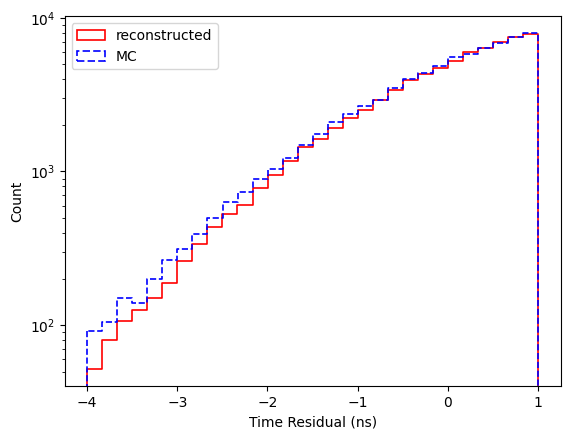

In [184]:
# Appy time residual cuts
time_residual_recons_cut = time_residual_recons[(time_residual_recons > tres_min) & (time_residual_recons < tres_max)]
time_residual_mc_cut = time_residual_mc[(time_residual_mc > tres_min) & (time_residual_mc < tres_max)]

sn.histplot(time_residual_recons_cut, bins = 30, element = 'step', alpha = 0, lw = 1.2, label = 'reconstructed', color = 'red')
sn.histplot(time_residual_mc_cut, bins = 30, element = 'step', alpha = 0, lw = 1.2, label = 'MC', color = 'blue', linestyle = '--')

plt.yscale('log')
plt.xlabel('Time Residual (ns)')
plt.legend()
plt.show()

### Reconstructed vs. Simulated (Chev. Hits)

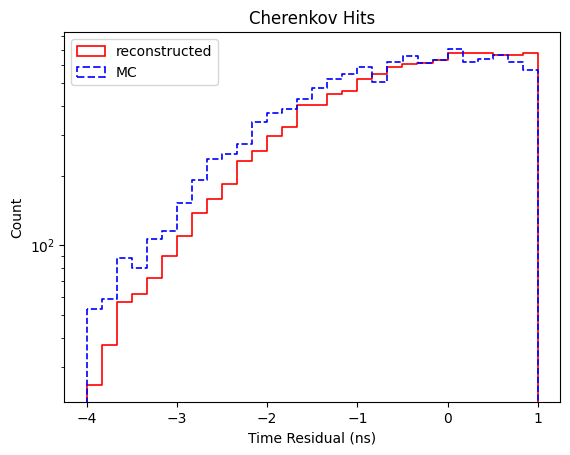

In [17]:
time_residual_cher_recons = time_rhit_type_cutesidual_recons[cher_hits_condition]
time_residual_cher_mc = time_residual_mc[cher_hits_condition]

# Appy time residual cuts
time_residual_cher_recons_cut = time_residual_cher_recons[(time_residual_cher_recons > tres_min) & (time_residual_cher_recons < tres_max)]
time_residual_cher_mc_cut = time_residual_cher_mc[(time_residual_cher_mc > tres_min) & (time_residual_cher_mc < tres_max)]

sn.histplot(time_residual_cher_recons_cut, bins = 30, element = 'step', alpha = 0, lw = 1.2, label = 'reconstructed', color = 'red')
sn.histplot(time_residual_cher_mc_cut, bins = 30, element = 'step', alpha = 0, lw = 1.2, label = 'MC', color = 'blue', linestyle = '--')

plt.yscale('log')
plt.xlabel('Time Residual (ns)')
plt.legend()
plt.title('Cherenkov Hits')
plt.show()

### Reconstructed vs. Simulated (Scint. Hits)

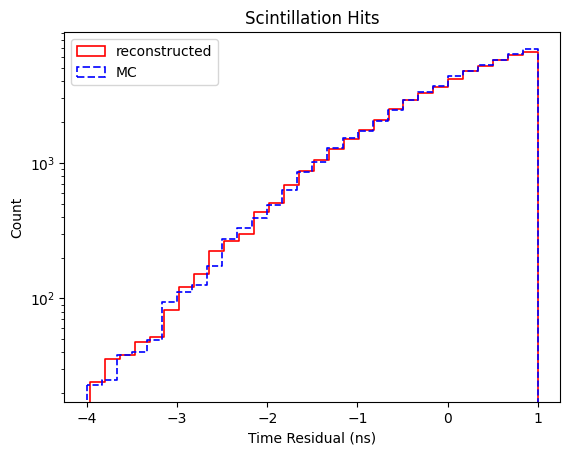

In [18]:
bins = 'auto'

time_residual_scint_recons = time_residual_recons[scint_hits_condition]
time_residual_scint_mc = time_residual_mc[scint_hits_condition]

# Appy time residual cuts
time_residual_scint_recons_cut = time_residual_scint_recons[(time_residual_scint_recons > tres_min) & (time_residual_scint_recons < tres_max)]
time_residual_scint_mc_cut = time_residual_scint_mc[(time_residual_scint_mc > tres_min) & (time_residual_scint_mc < tres_max)]

sn.histplot(time_residual_scint_recons_cut, bins = 30, element = 'step', alpha = 0, lw = 1.2, label = 'reconstructed', color = 'red')
sn.histplot(time_residual_scint_mc_cut, bins = 30, element = 'step', alpha = 0, lw = 1.2, label = 'MC', color = 'blue', linestyle = '--')

plt.yscale('log')
plt.xlabel('Time Residual (ns)')
plt.legend()
plt.title('Scintillation Hits')
plt.show()

## PMT Hit Time

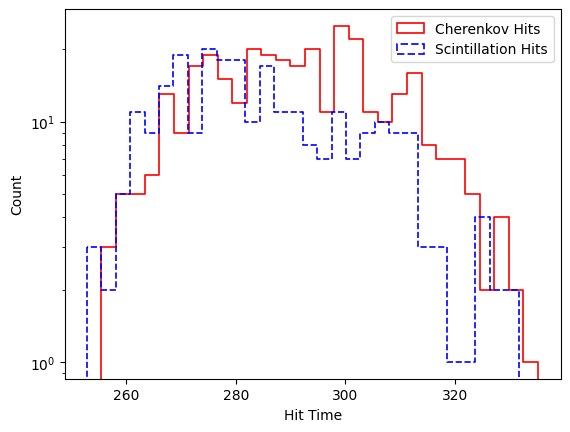

In [138]:
bins = 30

hit_time_cher = hit_time[cher_hits_condition]
hit_time_scint = hit_time[scint_hits_condition]

hit_time_cher_cut = hit_time_cher[(time_residual_cher > tres_min) & (time_residual_cher < tres_max)]
hit_time_scint_cut = hit_time_scint[(time_residual_scint > tres_min) & (time_residual_scint < tres_max)]

sn.histplot(hit_time_cher_cut, bins = bins, element = 'step', alpha = 0, lw = 1.2, label = 'Cherenkov Hits', color = 'red')
sn.histplot(hit_time_scint_cut, bins = bins, element = 'step', alpha = 0, lw = 1.2, label = 'Scintillation Hits', linestyle = '--', color = 'blue')

plt.yscale('log')
plt.xlabel(r'Hit Time')
plt.legend()
plt.show()

## Charge

It may be a trick. The Charge must be integrated for each PMT and then compare the PMT charges that observes Cher + Scint vs. the hits that only observes Scint.

### QHL

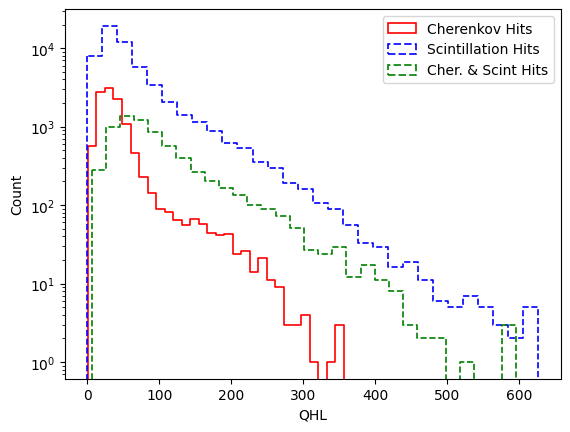

In [185]:
hit_qhl_cher = hit_qhl[cher_hits_condition]
hit_qhl_scint = hit_qhl[scint_hits_condition]
hit_qhl_cher_plus_scint = hit_qhl[cher_plus_scint_hits_condition]

hit_qhl_cher_cut = hit_qhl_cher[(time_residual_cher > tres_min) & (time_residual_cher < tres_max)]
hit_qhl_scint_cut = hit_qhl_scint[(time_residual_scint > tres_min) & (time_residual_scint < tres_max)]
hit_qhl_cher_plus_scint_cut = hit_qhl_cher_plus_scint[(time_residual_cher_plus_scint > tres_min) & (time_residual_cher_plus_scint < tres_max)]

sn.histplot(hit_qhl_cher_cut, bins = bins, element = 'step', alpha = 0, lw = 1.2, label = 'Cherenkov Hits', color = 'red')
sn.histplot(hit_qhl_scint_cut, bins = bins, element = 'step', alpha = 0, lw = 1.2, label = 'Scintillation Hits', linestyle = '--', color = 'blue')
sn.histplot(hit_qhl_cher_plus_scint_cut, bins = bins, element = 'step', alpha = 0, lw = 1.2, label = 'Cher. & Scint Hits', linestyle = '--', color = 'green')

plt.yscale('log')
plt.xlabel(r'QHL')
plt.legend()
plt.show()

### QHS

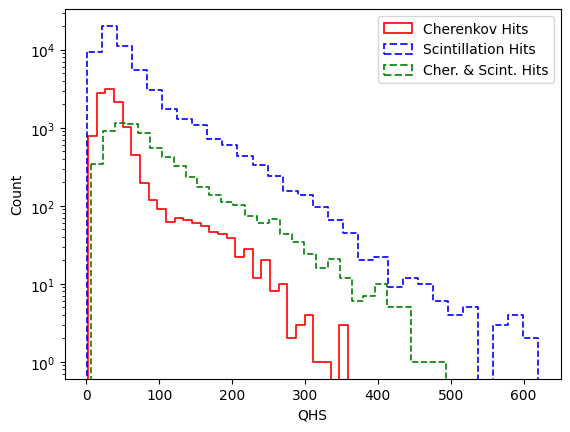

In [187]:
hit_qhs_cher = hit_qhs[cher_hits_condition]
hit_qhs_scint = hit_qhs[scint_hits_condition]
hit_qhs_cher_plus_scint = hit_qhs[cher_plus_scint_hits_condition]

hit_qhs_cher_cut = hit_qhs_cher[(time_residual_cher > tres_min) & (time_residual_cher < tres_max)]
hit_qhs_scint_cut = hit_qhs_scint[(time_residual_scint > tres_min) & (time_residual_scint < tres_max)]
hit_qhs_cher_plus_scint_cut = hit_qhs_cher_plus_scint[(time_residual_cher_plus_scint > tres_min) & (time_residual_cher_plus_scint < tres_max)]

sn.histplot(hit_qhs_cher_cut, bins = bins, element = 'step', alpha = 0, lw = 1.2, label = 'Cherenkov Hits', color = 'red')
sn.histplot(hit_qhs_scint_cut, bins = bins, element = 'step', alpha = 0, lw = 1.2, label = 'Scintillation Hits', linestyle = '--', color = 'blue')
sn.histplot(hit_qhs_cher_plus_scint_cut, bins = bins, element = 'step', alpha = 0, lw = 1.2, label = 'Cher. & Scint. Hits', linestyle = '--', color = 'green')

plt.yscale('log')
plt.xlabel(r'QHS')
plt.legend()
plt.show()

### Integrated Charge within Time Residual Window

Build the distributions of:

- PMT charge of cherenkov + scintillator hits
- PMT charge of only scintillator hits

For this we need to identify, event-by-event, the PMTs that are recording scintillation and cherenkov light and the PMTs that are only recording scintillation light. Then, sum the charge PMT by PMT and compare the integrated charge distribution of the scint+chev PMTs with the only-scint PMTs.

There are two funtions that will return the charge distribution of PMTs with hit_type=2 and hit_type=3. The analysis functions are:
1) The calculate_integrated_charge_per_event() function will compute the sum of all PMTs of the same hittype within an event.
2) The calculate_charge_per_pmt_hit_type_per_event() calculate the total charge observed by each PMT (keep PMTs separated, but labeled with its hit_type) within an event.

In [188]:
def calculate_integrated_charge_per_event(npz_file, t_min=-3.0, t_max=1.0, save_output=None):
    """
    Compute the total charge acumulated by each PMT hit type per event, i.e.,
    the charge of all PMTs is the summed for each hit_type.
    
    Compute the charge acumulated by each hit PMT id of each hit_type per event.
    The hit types of interest are hit_type = 2 (pure scintillator) and hit_type = 3 
    (Cherenkov plus scintillation light).
    
    The PMTs are selected only through a time residual cut.

    Parameters*:
    -npz_file: Directory where are the files to be analyzed in npz format.
    .t_min, t_max: min and max time residual window limits to select hit PMTs
    -save_output: defaul to None. Directory where to save the analysis results.

    Returns: results (npz array with the analysis results)
    """
    print(f"Loading Files: {npz_file}")
    data = np.load(npz_file)

    # Extract the data
    mcid = data['mcid']
    evtid = data['evtid']
    hit_pmt_id = data['hit_pmt_id']
    t_res = data['time_residual_recons'] 
    qhs = data['hit_qhs']
    hit_type = data['hit_type']

    # 1. Perform the tres cut
    time_mask = (t_res >= t_min) & (t_res <= t_max)

    mcid_cut = mcid[time_mask]
    evtid_cut = evtid[time_mask]
    hit_pmt_id_cut = hit_pmt_id[time_mask]
    qhs_cut = qhs[time_mask]
    hit_type_cut = hit_type[time_mask]

    # Identify the events: Use mcid and evtid to avoid mixing the events
    unique_events, event_indices = np.unique(
        np.column_stack((mcid_cut, evtid_cut)), axis=0, return_index=True
    )

    # Structure of the output/results
    results = {
        'mcid': [],
        'evtid': [],
        'q_tot_scint_only': [],   # Carga integrada de todos los hit_type == 2 por evento
        'q_tot_cher_scint': [],   # Carga integrada de todos los hit_type == 3 por evento
        'q_per_pmt_scint_only': [],       # Carga integrada de PMTs hit_type == 2 por evento
        'q_per_pmt_cher_scint': [],       # Carga integrada de PMTs hit_type == 3 por evento
        'norm_q_scint_only': [],  # Carga integrada de PMTs hit_type == 2 por evento normalizado por nhits
        'norm_q_cher_scint': [],  # Carga integrada de PMTs hit_type == 3 por evento normalizado por nhits
        'nhits_scint_only': [],   # Número de hits/PMTs de tipo 2 en la ventana
        'nhits_cher_scint': []    # Número de hits/PMTs de tipo 3 en la ventana
    }

    # 2. Event by event analysis
    for evt_mc, evt_gtid in unique_events:
        # Mask to select event-by-event through mcid and eventID entries
        mask_evt = (mcid_cut == evt_mc) & (evtid_cut == evt_gtid)

        hit_pmt_id_evt = hit_pmt_id_cut[mask_evt]
        q_evt = qhs_cut[mask_evt]
        ht_evt = hit_type_cut[mask_evt]

        # hit_type masks
        mask_type2 = (ht_evt == 2) 
        mask_type3 = (ht_evt == 3) #| (ht_evt == 1)

        # NHits of each type within the event
        nhits_type2 = np.sum(mask_type2)
        nhits_type3 = np.sum(mask_type3)

        # Charge Integration of all PMTs wihtin and event for each hit type
        q_sum_type2 = np.sum(q_evt[mask_type2]) if np.any(mask_type2) else 0.0
        q_sum_type3 = np.sum(q_evt[mask_type3]) if np.any(mask_type3) else 0.0

        #Charge integration for each PMT hit id within an event foe each hit_type
        hit_pmtid_type2 = hit_pmt_id_evt[mask_type2]
        hit_pmtid_type3 = hit_pmt_id_evt[mask_type3]

        unique_pmtid_type2 = np.unique(hit_pmtid_type2, axis = 0)
        unique_pmtid_type3 = np.unique(hit_pmtid_type3, axis = 0)

        q_evt_type2 = q_evt[mask_type2]
        q_evt_type3 = q_evt[mask_type3]

        # Iteration over hit PMT ID for each hit_type:
        for hit_id_i in unique_pmtid_type2:
            # Mask to select only this hit PMT ID
            mask_pmtid = (hit_pmtid_type2 == hit_id_i)

            q_evt_pmtid = q_evt_type2[mask_pmtid]
            q_sum_pmt = np.sum(q_evt_pmtid)

            # Integrate the charge observed by this PMT
            results['q_per_pmt_scint_only'].append(q_sum_pmt)
            results['norm_q_scint_only'].append(q_sum_pmt/nhits_type2)

        for hit_id_i in unique_pmtid_type3:
            # Mask to select only this hit PMT ID
            mask_pmtid = (hit_pmtid_type3 == hit_id_i)

            q_evt_pmtid = q_evt_type3[mask_pmtid]
            q_sum_pmt = np.sum(q_evt_pmtid)
            
            # Save the Integrated and normalized charge observed by this PMT
            results['q_per_pmt_cher_scint'].append(q_sum_pmt)
            results['norm_q_cher_scint'].append(q_sum_pmt/nhits_type3)

        # save the results
        results['mcid'].append(evt_mc)
        results['evtid'].append(evt_gtid)
        results['q_tot_scint_only'].append(q_sum_type2)
        results['q_tot_cher_scint'].append(q_sum_type3)
        results['nhits_scint_only'].append(nhits_type2)
        results['nhits_cher_scint'].append(nhits_type3)

    # Transform to numpy arrays
    for k in results:
        results[k] = np.array(results[k])

    print(f"Events Analyzed: {len(results['mcid'])}")

    # 3. Guardar el resultado procesado si se especifica ruta de guardado
    if save_output:
        np.savez(save_output, **results)
        print(f"Cargas integradas guardadas en: {save_output}")

    return results

In [175]:
def calculate_charge_per_pmt_hit_type_per_event(npz_file, t_min=-3.0, t_max=1.0, save_output=None):
    """
    Compute the charge acumulated by each PMT hit type per event.
    The hit types of interest are hit_type = 2 (pure scintillator) and
    hit_type = 3 (Cherenkov plus scintillation light).
    The PMTs are selected only through a time residual cut.

    Parameters*:
    -npz_file: Directory where are the files to be analyzed in npz format.
    .t_min, t_max: defaul to (t_min, t_max) = (-3, 1) ns.  Min and max time residual window limits to select hit PMTs
    -save_output: defaul to None. Directory where to save the analysis results.

    Returns: results (npz array with the analysis results)
    """
    print(f"Loading Files: {npz_file}")
    data = np.load(npz_file)

    # Extract the data
    mcid = data['mcid']
    evtid = data['evtid']
    hit_pmt_id = data['hit_pmt_id']
    t_res = data['time_residual_recons'] 
    qhs = data['hit_qhs']
    hit_type = data['hit_type']

    # 1. Perform the tres cut
    time_mask = (t_res >= t_min) & (t_res <= t_max)

    mcid_cut = mcid[time_mask]
    evtid_cut = evtid[time_mask]
    hit_pmt_id_cut = hit_pmt_id[time_mask]
    qhs_cut = qhs[time_mask]
    hit_type_cut = hit_type[time_mask]

    # Identify the events: Use mcid and evtid to avoid mixing the events
    unique_events, event_indices = np.unique(
        np.column_stack((mcid_cut, evtid_cut)), axis = 0, return_index = True)

    # Structure of the output/results
    results = {
        #'mcid': [],
        #'evtid': [],
        'q_scint_only': [],       # Carga integrada de PMTs hit_type == 2
        'q_cher_scint': [],       # Carga integrada de PMTs hit_type == 3
        #'nhits_scint_only': [],   # Número de hits/PMTs de tipo 2 en la ventana
        #'nhits_cher_scint': []    # Número de hits/PMTs de tipo 3 en la ventana
    }
    
    # 2. Event by event analysis
    for evt_mc, evt_gtid in unique_events:
        # Mask to select event-by-event through mcid and eventID entries
        mask_evt = (mcid_cut == evt_mc) & (evtid_cut == evt_gtid)

        hit_pmt_id_evt = hit_pmt_id_cut[mask_evt]
        q_evt = qhs_cut[mask_evt]
        ht_evt = hit_type_cut[mask_evt]

        # hit_type masks to separate PMT hit types 
        mask_type2 = (ht_evt == 2) 
        mask_type3 = (ht_evt == 3)

        hit_pmtid_type2 = hit_pmt_id_evt[mask_type2]
        hit_pmtid_type3 = hit_pmt_id_evt[mask_type3]

        unique_pmtid_type2 = np.unique(hit_pmtid_type2, axis = 0)
        unique_pmtid_type3 = np.unique(hit_pmtid_type3, axis = 0)

        q_evt_type2 = q_evt[mask_type2]
        q_evt_type3 = q_evt[mask_type3]

        # Iteration over hit PMT ID for each hit_type:
        for hit_id_i in unique_pmtid_type2:
            # Mask to select only this hit PMT ID
            mask_pmtid = (hit_pmtid_type2 == hit_id_i)

            q_evt_pmtid = q_evt_type2[mask_pmtid]

            # Integrate the charge observed by this PMT
            results['q_scint_only'].append(np.sum(q_evt_pmtid))

        for hit_id_i in unique_pmtid_type3:
            # Mask to select only this hit PMT ID
            mask_pmtid = (hit_pmtid_type3 == hit_id_i)

            q_evt_pmtid = q_evt_type3[mask_pmtid]

            # Integrate the charge observed by this PMT
            results['q_cher_scint'].append(np.sum(q_evt_pmtid))
            
    # Transform to numpy arrays
    for k in results:
        results[k] = np.array(results[k])

    #print(f"Events Analyzed: {len(results['mcid'])}")

    # 3. Guardar el resultado procesado si se especifica ruta de guardado
    if save_output:
        np.savez(save_output, **results)
        print(f"Cargas integradas guardadas en: {save_output}")
    print('Analysis finished')

    return results

In [189]:
# --------- Total PMT hit type charge per event results ---------
results = calculate_integrated_charge_per_event(fdir, t_min=-3, t_max=1)
q_tot_scint_only = results['q_tot_scint_only']
q_tot_cher_scint = results['q_tot_cher_scint']

q_per_pmt_scint_only = results['q_per_pmt_scint_only']
q_per_pmt_cher_scint = results['q_per_pmt_cher_scint']

norm_q_per_pmt_scint_only = results['norm_q_scint_only']
norm_q_per_pmt_cher_scint = results['norm_q_cher_scint']

nhits_scint_only = results['nhits_scint_only']
nhits_cher_scint = results['nhits_cher_scint']

# remove null charges (remove artifical peak at zero produced in the analysis code)
nhits_scint_only = nhits_scint_only[q_tot_scint_only>0]
nhits_cher_scint = nhits_cher_scint[q_tot_cher_scint>0]
q_tot_scint_only = q_tot_scint_only[q_tot_scint_only>0]
q_tot_cher_scint = q_tot_cher_scint[q_tot_cher_scint>0]

# Compute the  Normalized charges by the number of hits of each type on the total charge integration
norm_q_tot_scint_only = q_tot_scint_only / nhits_scint_only
norm_q_tot_norm_cher_scint = q_tot_cher_scint / nhits_cher_scint

Loading Files: /home/joankl/data/solars/mc/2p2PPO/electrons/e_5.0MeV_0.npz
Events Analyzed: 982


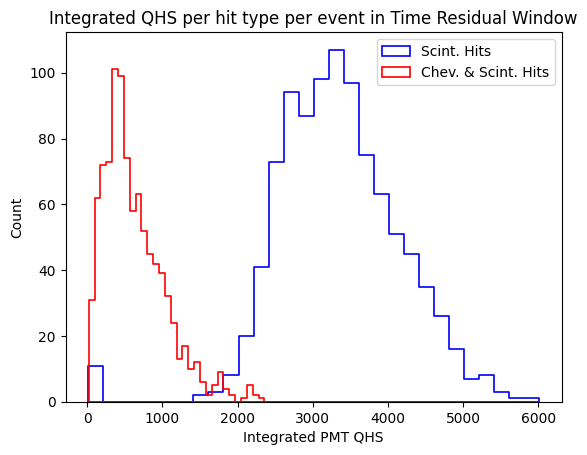

In [190]:
bins = 30

sn.histplot(q_tot_scint_only, bins = bins, element = 'step', alpha = 0, lw = 1.2, label = 'Scint. Hits', color = 'blue')
sn.histplot(q_tot_cher_scint, bins = bins, element = 'step', alpha = 0, lw = 1.2, label = 'Chev. & Scint. Hits', color = 'red')

plt.xlabel('Integrated PMT QHS')

plt.legend()
#plt.yscale('log')
plt.title('Integrated QHS per hit type per event in Time Residual Window')

plt.show()

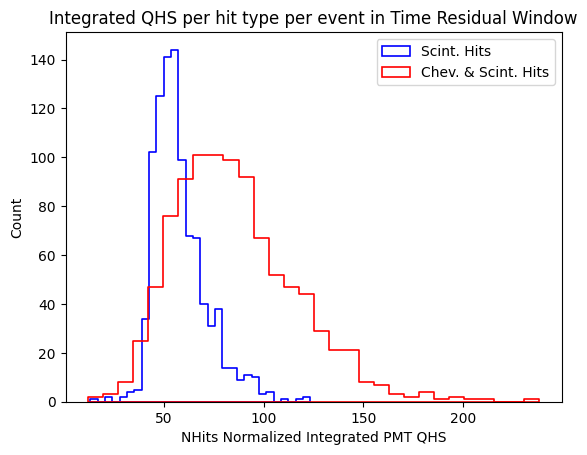

In [191]:
bins = 30

sn.histplot(norm_q_tot_scint_only, bins = bins, element = 'step', alpha = 0, lw = 1.2, label = 'Scint. Hits', color = 'blue')
sn.histplot(norm_q_tot_norm_cher_scint, bins = bins, element = 'step', alpha = 0, lw = 1.2, label = 'Chev. & Scint. Hits', color = 'red')

plt.xlabel('NHits Normalized Integrated PMT QHS')

plt.legend()
#plt.yscale('log')
plt.title('Integrated QHS per hit type per event in Time Residual Window')

plt.show()

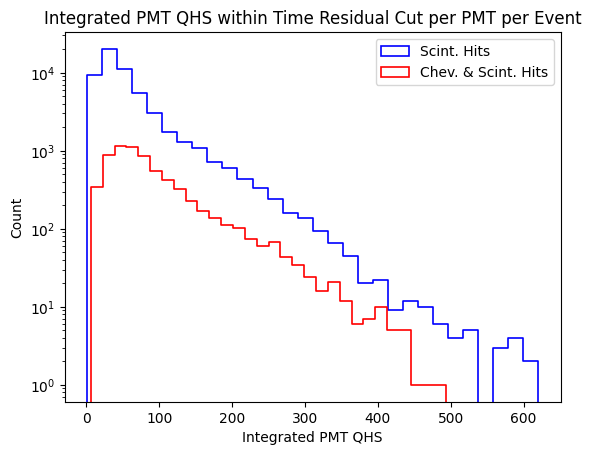

In [192]:
bins = 30

sn.histplot(q_per_pmt_scint_only, bins = bins, element = 'step', alpha = 0, lw = 1.2, label = 'Scint. Hits', color = 'blue')
sn.histplot(q_per_pmt_cher_scint, bins = bins, element = 'step', alpha = 0, lw = 1.2, label = 'Chev. & Scint. Hits', color = 'red')

plt.xlabel('Integrated PMT QHS')

plt.legend()

plt.yscale('log')
plt.title('Integrated PMT QHS within Time Residual Cut per PMT per Event')

plt.show()

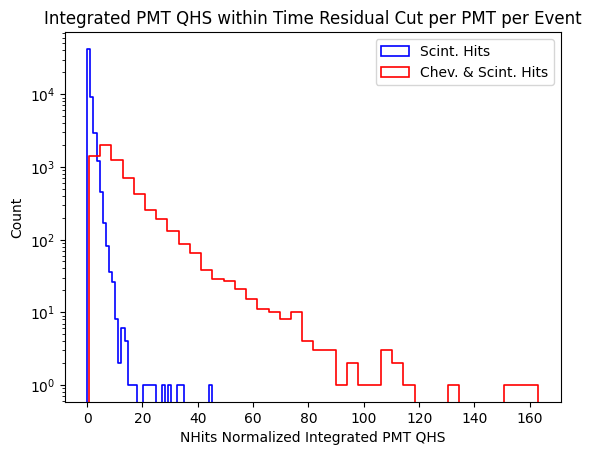

In [193]:
bins = 40

sn.histplot(norm_q_per_pmt_scint_only, bins = bins, element = 'step', alpha = 0, lw = 1.2, label = 'Scint. Hits', color = 'blue')
sn.histplot(norm_q_per_pmt_cher_scint, bins = bins, element = 'step', alpha = 0, lw = 1.2, label = 'Chev. & Scint. Hits', color = 'red')

plt.xlabel('NHits Normalized Integrated PMT QHS')

plt.legend()

plt.yscale('log')
plt.title('Integrated PMT QHS within Time Residual Cut per PMT per Event')

plt.show()